In [35]:
!pip install -q pandas numpy scikit-learn joblib matplotlib seaborn

In [36]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"], errors="ignore")
df = df.dropna()
X = df.drop(columns=["Exited"])
y = df["Exited"].astype(int)
print("Features kept:", X.columns.tolist())
print("Features count:", X.shape[1])
print("Customers:", len(X))
print("\nTarget distribution:")
print(y.value_counts())

Features kept: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'IsActiveMember']
Features count: 8
Customers: 10000

Target distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


Based on the correlation and statistical test outputs, we can make informed decisions about dropping features that have virtually no statistical relationship with the target.

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [38]:
from sklearn.ensemble import RandomForestClassifier
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])
model.fit(X_train, y_train)
print("Training completed!")

Training completed!


Accuracy: 0.855
ROC-AUC: 0.8596

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.91      0.91      1593
           1       0.65      0.62      0.64       407

    accuracy                           0.85      2000
   macro avg       0.78      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



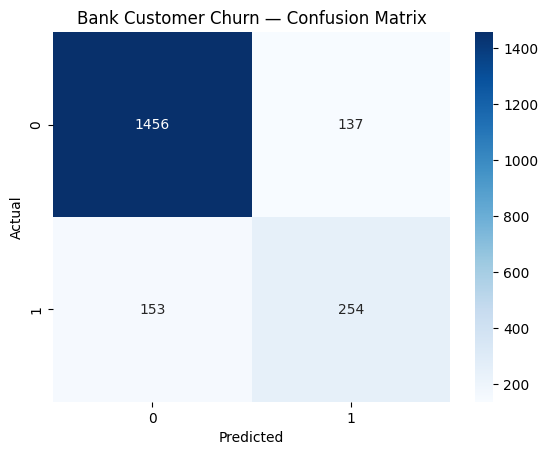

In [39]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Bank Customer Churn — Confusion Matrix")
plt.show()

In [40]:
import joblib
joblib.dump(model, "model.joblib")
print("Model saved successfully!")
loaded_model = joblib.load("model.joblib")
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0][1]
print("Predicted churn:", int(prediction))
print("Churn probability:", round(float(probability), 4))

Model saved successfully!
Predicted churn: 0
Churn probability: 0.0565
